In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)

print("Environment initialized successfully.")

Environment initialized successfully.


In [2]:
import os

print("Files currently in /content:")
print(os.listdir("/content"))

Files currently in /content:
['.config', 'sample_data']


In [3]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Saving European_Bank.csv to European_Bank.csv
Loaded successfully!
Shape: (10000, 14)


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


#Data Preprocessing
* Handle missing values
* Remove non-informative features (CustomerId, Surname)
* Encode categorical variables:
One-hot encoding (Geography, Gender)
* Scale numerical features where required


In [4]:
# Dataset overview
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 records:")
display(df.head())

Dataset shape: (10000, 14)

Column names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int6

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
display(df.nunique().sort_values(ascending=False))

print("\nTarget distribution:")
display(df["Exited"].value_counts(dropna=False))

print("\nTarget distribution (%):")
display(
    (df["Exited"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Missing values:


,0
Year,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0



Duplicate rows: 0

Unique values per column:


,0
CustomerId,10000
EstimatedSalary,9999
Balance,6382
Surname,2932
CreditScore,460
Age,70
Tenure,11
NumOfProducts,4
Geography,3
Gender,2



Target distribution:


,count
Exited,
0,7963
1,2037



Target distribution (%):


,proportion
Exited,
0,79.63
1,20.37


In [6]:
if "Year" in df.columns:
    print("Unique years:", sorted(df["Year"].dropna().unique()))
    print("\nRecords per year:")
    display(df["Year"].value_counts(dropna=False).sort_index())
else:
    print("No Year column found.")

Unique years: [np.int64(2025)]

Records per year:


,count
Year,
2025,10000


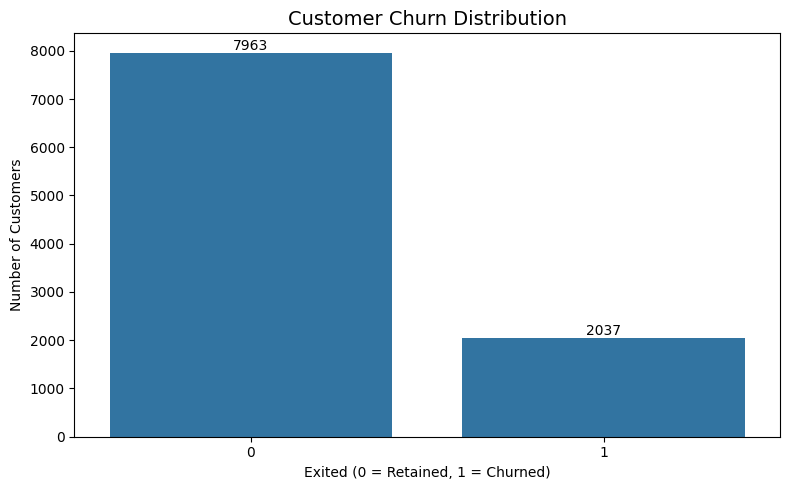

In [7]:
# Target distribution visualization

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Exited"
)

ax.set_title("Customer Churn Distribution", fontsize=14)
ax.set_xlabel("Exited (0 = Retained, 1 = Churned)")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [8]:
def analyze_churn_by_category(column):
    """
    Calculate customer counts and churn rates
    for each category of a feature.
    """

    summary = (
        df.groupby(column, observed=True)["Exited"]
        .agg(
            Customers="count",
            Churned="sum",
            Churn_Rate="mean"
        )
        .reset_index()
    )

    summary["Churn_Rate"] *= 100

    return summary.sort_values(
        "Churn_Rate",
        ascending=False
    )

,Geography,Customers,Churned,Churn_Rate
1,Germany,2509,814,32.44%
2,Spain,2477,413,16.67%
0,France,5014,810,16.15%


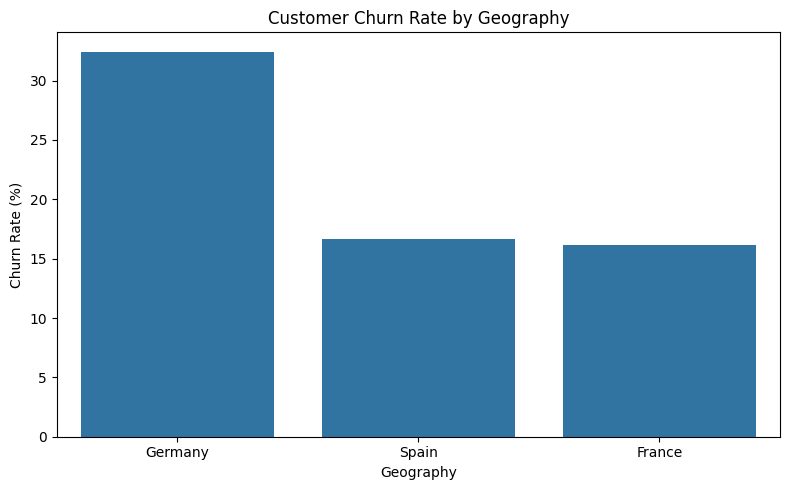

In [9]:
geo_summary = analyze_churn_by_category("Geography")

display(
    geo_summary.style.format({
        "Churn_Rate": "{:.2f}%"
    })
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=geo_summary,
    x="Geography",
    y="Churn_Rate"
)

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

,Activity_Status,Customers,Churned,Churn_Rate
0,Inactive,4849,1302,26.85%
1,Active,5151,735,14.27%


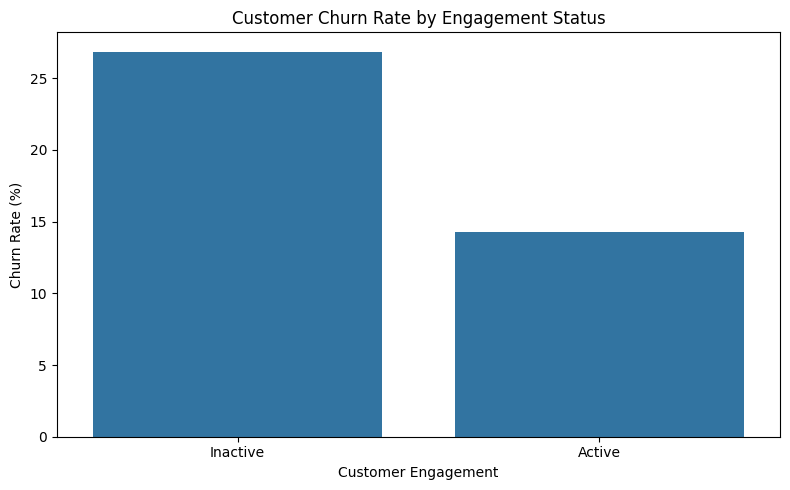

In [10]:
# Customer churn analysis by engagement status

activity_summary = analyze_churn_by_category(
    "IsActiveMember"
)

activity_summary["Activity_Status"] = (
    activity_summary["IsActiveMember"]
    .map({
        0: "Inactive",
        1: "Active"
    })
)

display(
    activity_summary[
        [
            "Activity_Status",
            "Customers",
            "Churned",
            "Churn_Rate"
        ]
    ].style.format({
        "Churn_Rate": "{:.2f}%"
    })
)

# Visualize churn rates
plt.figure(figsize=(8, 5))

sns.barplot(
    data=activity_summary,
    x="Activity_Status",
    y="Churn_Rate"
)

plt.title("Customer Churn Rate by Engagement Status")
plt.xlabel("Customer Engagement")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

,NumOfProducts,Customers,Churned,Churn_Rate
3,4,60,60,100.00%
2,3,266,220,82.71%
0,1,5084,1409,27.71%
1,2,4590,348,7.58%


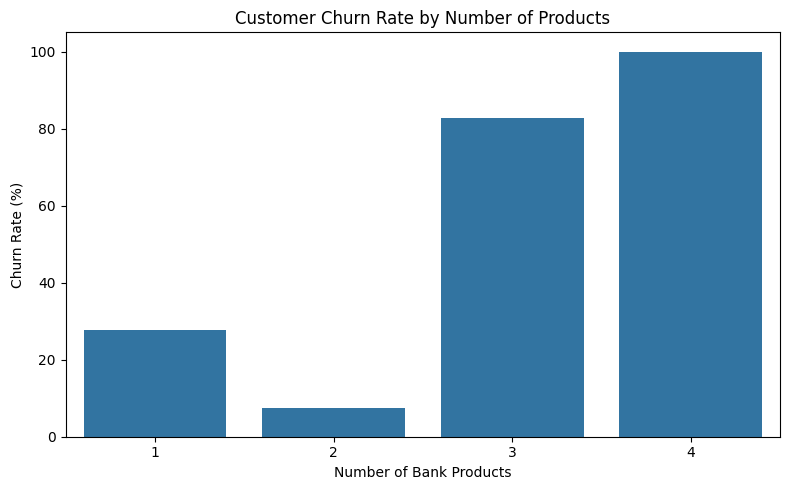

In [11]:
product_summary = analyze_churn_by_category(
    "NumOfProducts"
)

display(
    product_summary.style.format({
        "Churn_Rate": "{:.2f}%"
    })
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_summary,
    x="NumOfProducts",
    y="Churn_Rate"
)

plt.title("Customer Churn Rate by Number of Products")
plt.xlabel("Number of Bank Products")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

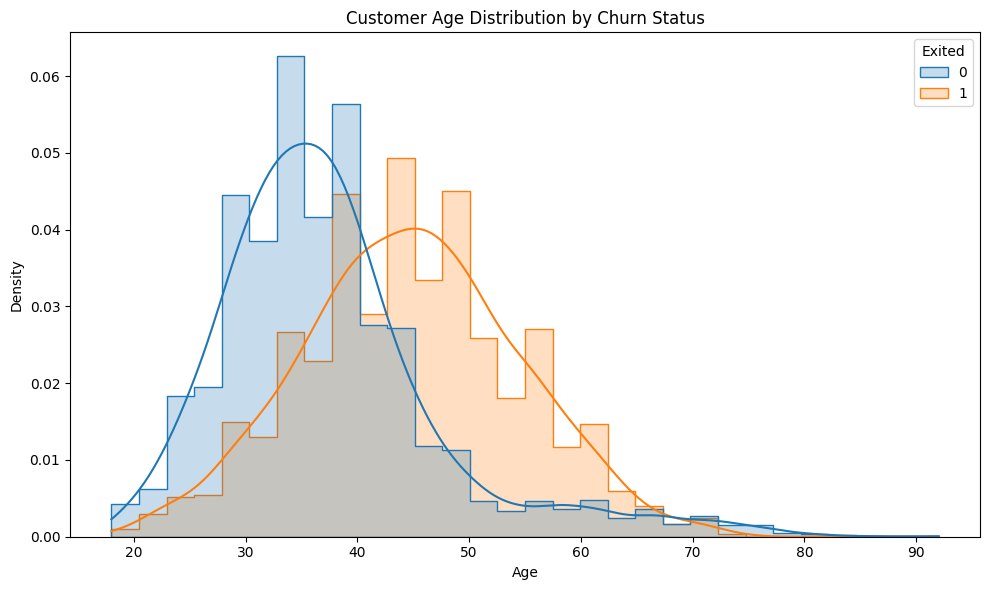

In [12]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Customer Age Distribution by Churn Status")
plt.xlabel("Age")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [13]:
age_summary = (
    df.groupby("Exited")["Age"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
)

age_summary.index = age_summary.index.map({
    0: "Retained",
    1: "Churned"
})

display(age_summary.round(2))

,Count,Mean,Median,Std_Dev
Exited,,,,
Retained,7963,37.41,36.0,10.13
Churned,2037,44.84,45.0,9.76


In [14]:
df["ZeroBalance"] = (
    df["Balance"] == 0
).astype(int)

balance_summary = (
    df.groupby("Exited")
    .agg(
        Customers=("Exited", "size"),
        Mean_Balance=("Balance", "mean"),
        Median_Balance=("Balance", "median"),
        Zero_Balance_Customers=("ZeroBalance", "sum")
    )
)

balance_summary.index = balance_summary.index.map({
    0: "Retained",
    1: "Churned"
})

balance_summary["Zero_Balance_Percent"] = (
    balance_summary["Zero_Balance_Customers"]
    / balance_summary["Customers"]
    * 100
)

display(balance_summary.round(2))

,Customers,Mean_Balance,Median_Balance,Zero_Balance_Customers,Zero_Balance_Percent
Exited,,,,,
Retained,7963,72745.30,92072.68,3117,39.14
Churned,2037,91108.54,109349.29,500,24.55


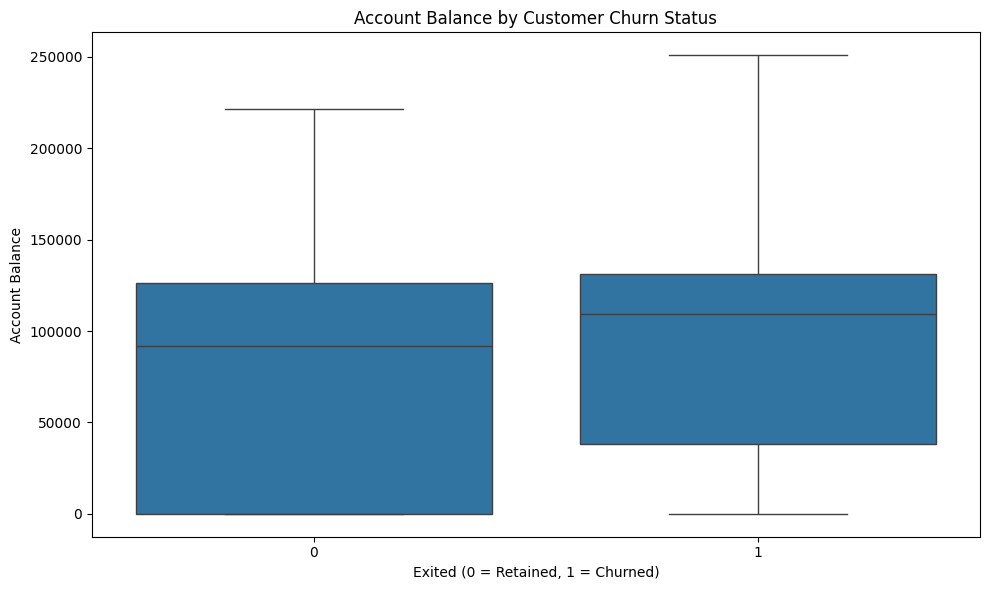

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

plt.title("Account Balance by Customer Churn Status")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Account Balance")

plt.tight_layout()
plt.show()

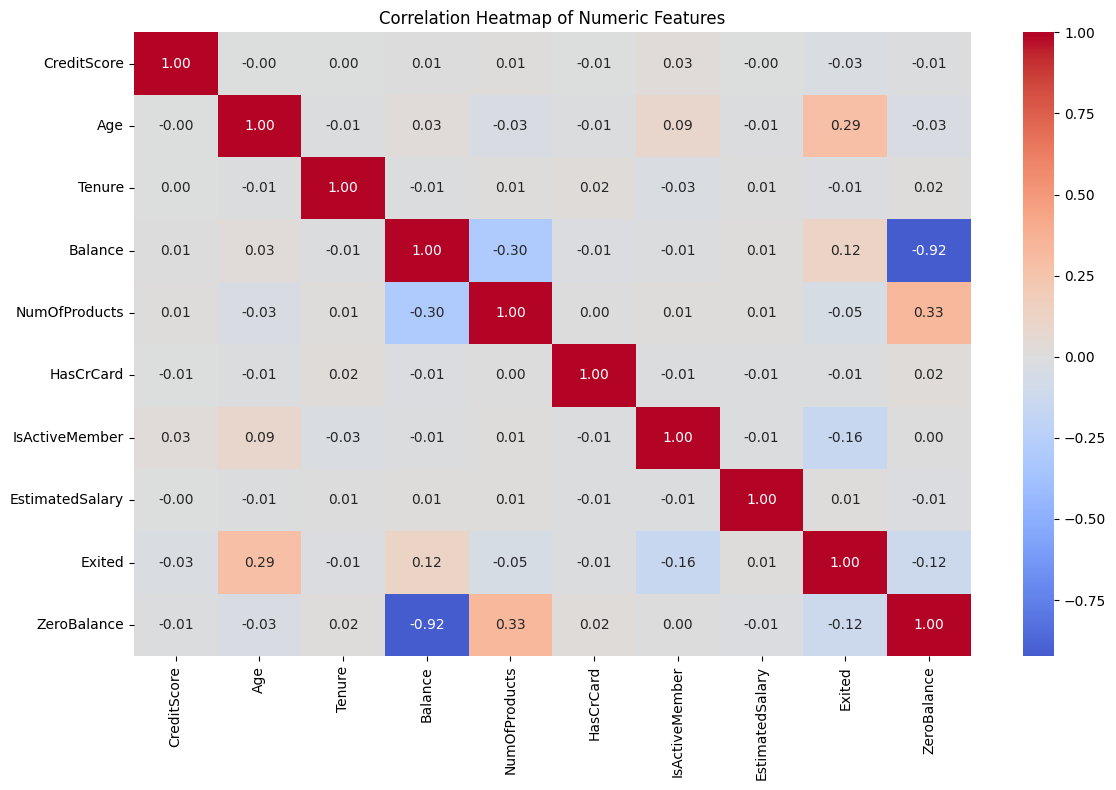

In [16]:
# Correlation analysis of numerical features

numeric_df = df.select_dtypes(
    include=["number"]
).drop(
    columns=[
        "Year",
        "CustomerId"
    ],
    errors="ignore"
)

correlation_matrix = numeric_df.corr(
    numeric_only=True
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numeric Features")

plt.tight_layout()
plt.show()

In [17]:
print("=" * 55)
print("CHURN RATE BY GEOGRAPHY")
print("=" * 55)
print(geo_summary.round(2).to_string(index=False))

print("\n" + "=" * 55)
print("CHURN RATE BY ACTIVITY STATUS")
print("=" * 55)
print(
    activity_summary[
        ["Activity_Status", "Customers", "Churned", "Churn_Rate"]
    ].round(2).to_string(index=False)
)

print("\n" + "=" * 55)
print("CHURN RATE BY NUMBER OF PRODUCTS")
print("=" * 55)
print(product_summary.round(2).to_string(index=False))

CHURN RATE BY GEOGRAPHY
Geography  Customers  Churned  Churn_Rate
  Germany       2509      814       32.44
    Spain       2477      413       16.67
   France       5014      810       16.15

CHURN RATE BY ACTIVITY STATUS
Activity_Status  Customers  Churned  Churn_Rate
       Inactive       4849     1302       26.85
         Active       5151      735       14.27

CHURN RATE BY NUMBER OF PRODUCTS
 NumOfProducts  Customers  Churned  Churn_Rate
             4         60       60      100.00
             3        266      220       82.71
             1       5084     1409       27.71
             2       4590      348        7.58


In [18]:
# ==========================================
# FEATURE ENGINEERING
# ==========================================

df_model = df.copy()

# 1. Remove non-informative columns
df_model = df_model.drop(
    columns=[
        "Year",
        "CustomerId",
        "Surname"
    ],
    errors="ignore"
)

# 2. Balance-to-salary ratio
# Protect against zero denominators.
df_model["BalanceSalaryRatio"] = (
    df_model["Balance"]
    / df_model["EstimatedSalary"].replace(0, np.nan)
)

# 3. Product-engagement interaction
df_model["ProductEngagement"] = (
    df_model["NumOfProducts"]
    * df_model["IsActiveMember"]
)

# 4. Age-tenure interaction
df_model["AgeTenureInteraction"] = (
    df_model["Age"]
    * df_model["Tenure"]
)

# Check the result
print("Original dataset shape:", df.shape)
print("Model dataset shape:", df_model.shape)

print("\nColumns available for modeling:")
print(df_model.columns.tolist())

print("\nMissing values after feature engineering:")
display(
    df_model.isnull().sum()[
        df_model.isnull().sum() > 0
    ]
)

print("\nPreview:")
display(df_model.head())

Original dataset shape: (10000, 15)
Model dataset shape: (10000, 15)

Columns available for modeling:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'ZeroBalance', 'BalanceSalaryRatio', 'ProductEngagement', 'AgeTenureInteraction']

Missing values after feature engineering:


,0



Preview:


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,ZeroBalance,BalanceSalaryRatio,ProductEngagement,AgeTenureInteraction
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,0.000000,1,84
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0,0.744677,1,41
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0,1.401375,0,336
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,1,0.000000,0,39
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,1.587055,1,86


In [19]:
# ==========================================
# DEFINE FEATURES AND TARGET
# ==========================================

X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Feature matrix shape: (10000, 14)
Target shape: (10000,)

Target distribution:


,proportion
Exited,
0,79.63
1,20.37


In [20]:
# ==========================================
# TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution (%):")
display(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting target distribution (%):")
display(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

Training records: 8000
Testing records: 2000

Training target distribution (%):


,proportion
Exited,
0,79.62
1,20.38



Testing target distribution (%):


,proportion
Exited,
0,79.65
1,20.35


In [21]:
# ==========================================
# PREPROCESSING PIPELINE
# ==========================================

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'ZeroBalance', 'BalanceSalaryRatio', 'ProductEngagement', 'AgeTenureInteraction']

Categorical features:
['Geography', 'Gender']

Preprocessing pipeline created successfully.


In [22]:
# Baseline Model: Logistic Regression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression baseline trained successfully.")

Logistic Regression baseline trained successfully.


In [23]:
# Generate class predictions and churn probabilities

y_pred_logistic = logistic_model.predict(X_test)

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated.")
print("Number of predictions:", len(y_pred_logistic))
print("Number of churn probabilities:", len(y_prob_logistic))

print("\nFirst 10 predicted classes:")
print(y_pred_logistic[:10])

print("\nFirst 10 churn probabilities:")
print(np.round(y_prob_logistic[:10], 4))

Predictions generated.
Number of predictions: 2000
Number of churn probabilities: 2000

First 10 predicted classes:
[0 1 0 0 0 0 0 1 1 0]

First 10 churn probabilities:
[0.3016 0.5575 0.3639 0.3656 0.2965 0.3598 0.2886 0.6603 0.6948 0.4781]


In [24]:
# Evaluate Logistic Regression

logistic_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Precision": precision_score(y_test, y_pred_logistic, zero_division=0),
    "Recall": recall_score(y_test, y_pred_logistic, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_logistic, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logistic)
}

logistic_results = pd.DataFrame(
    [logistic_metrics],
    index=["Logistic Regression"]
)

display(logistic_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["Retained", "Churned"],
    zero_division=0
))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.711,0.3852,0.7052,0.4983,0.7761



Classification Report:
              precision    recall  f1-score   support

    Retained       0.90      0.71      0.80      1593
     Churned       0.39      0.71      0.50       407

    accuracy                           0.71      2000
   macro avg       0.64      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000



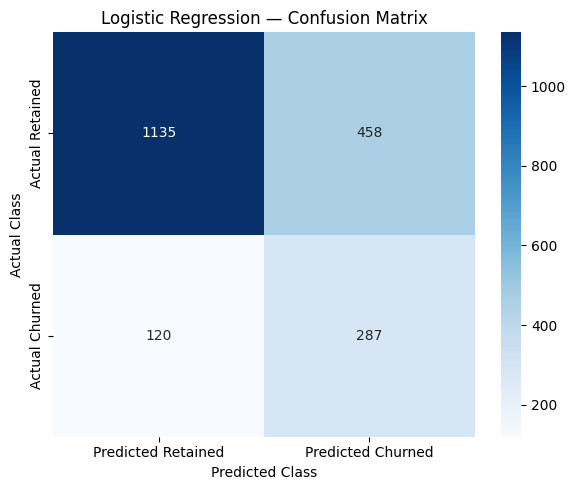

In [25]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Retained", "Predicted Churned"],
    yticklabels=["Actual Retained", "Actual Churned"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [26]:
# Train three tree-based classification models

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=10,
        random_state=RANDOM_STATE
    ))
])

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

for name, model in models.items():
    if name == "Logistic Regression":
        continue

    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Decision Tree trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.


In [27]:
# Evaluate all models on the same test set

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(
    results_df.sort_values(
        by="ROC-AUC",
        ascending=False
    ).round(4)
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Gradient Boosting,0.8690,0.7959,0.4791,0.5982,0.8693
Random Forest,0.8365,0.5855,0.6732,0.6263,0.8665
Decision Tree,0.7670,0.4552,0.7371,0.5629,0.8233
Logistic Regression,0.7110,0.3852,0.7052,0.4983,0.7761


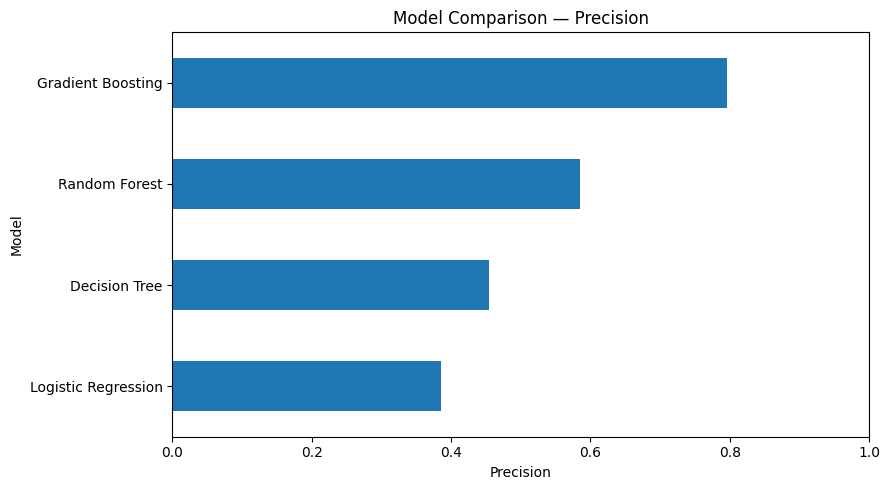

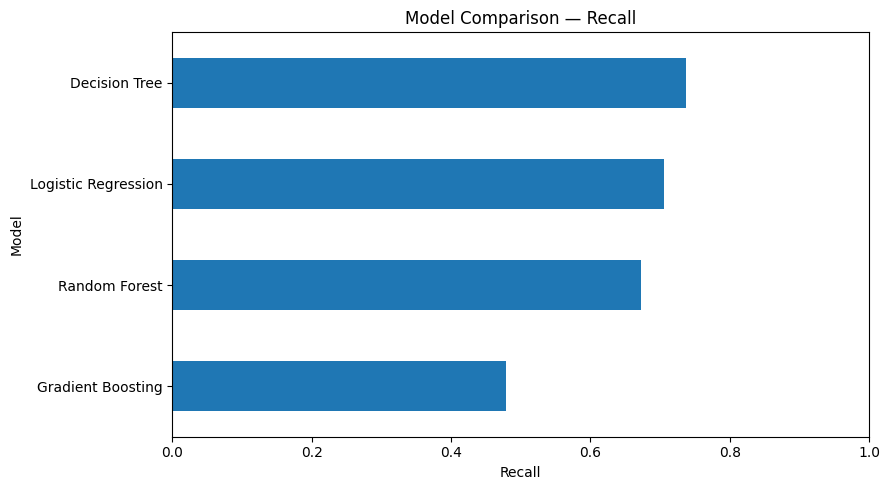

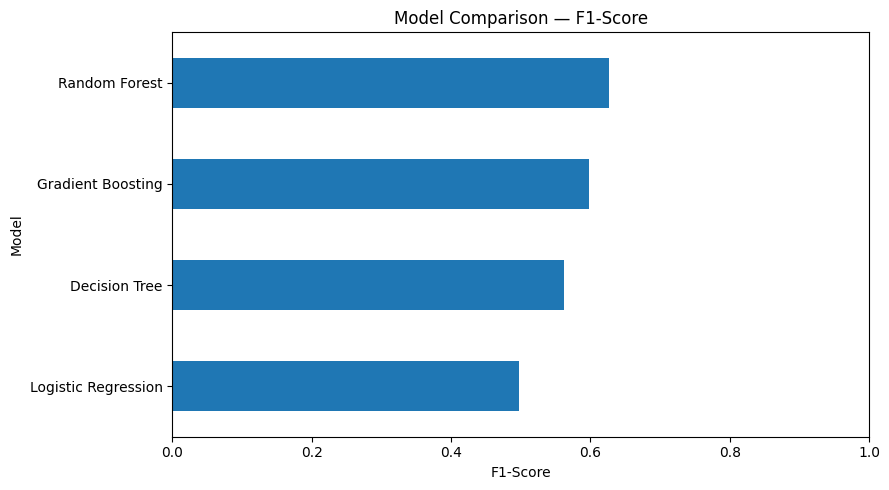

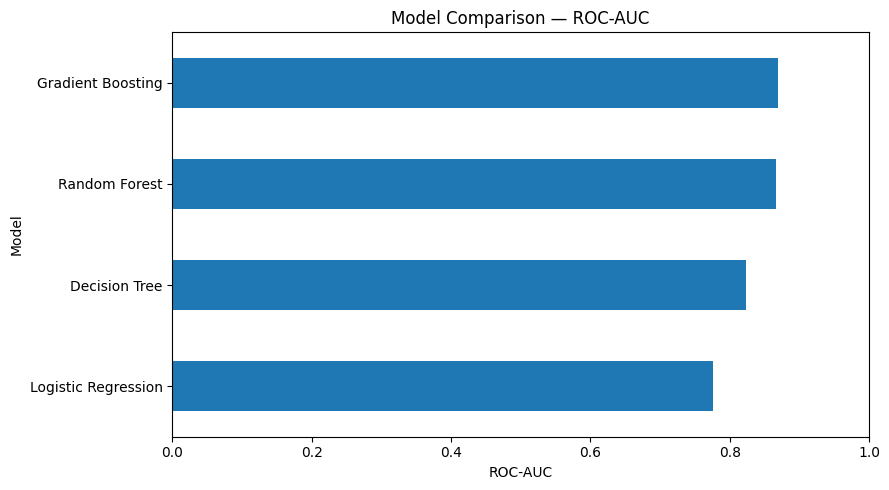

In [28]:
# Compare model performance across evaluation metrics

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(9, 5))

    results_df[metric].sort_values().plot(
        kind="barh"
    )

    plt.title(f"Model Comparison — {metric}")
    plt.xlabel(metric)
    plt.ylabel("Model")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

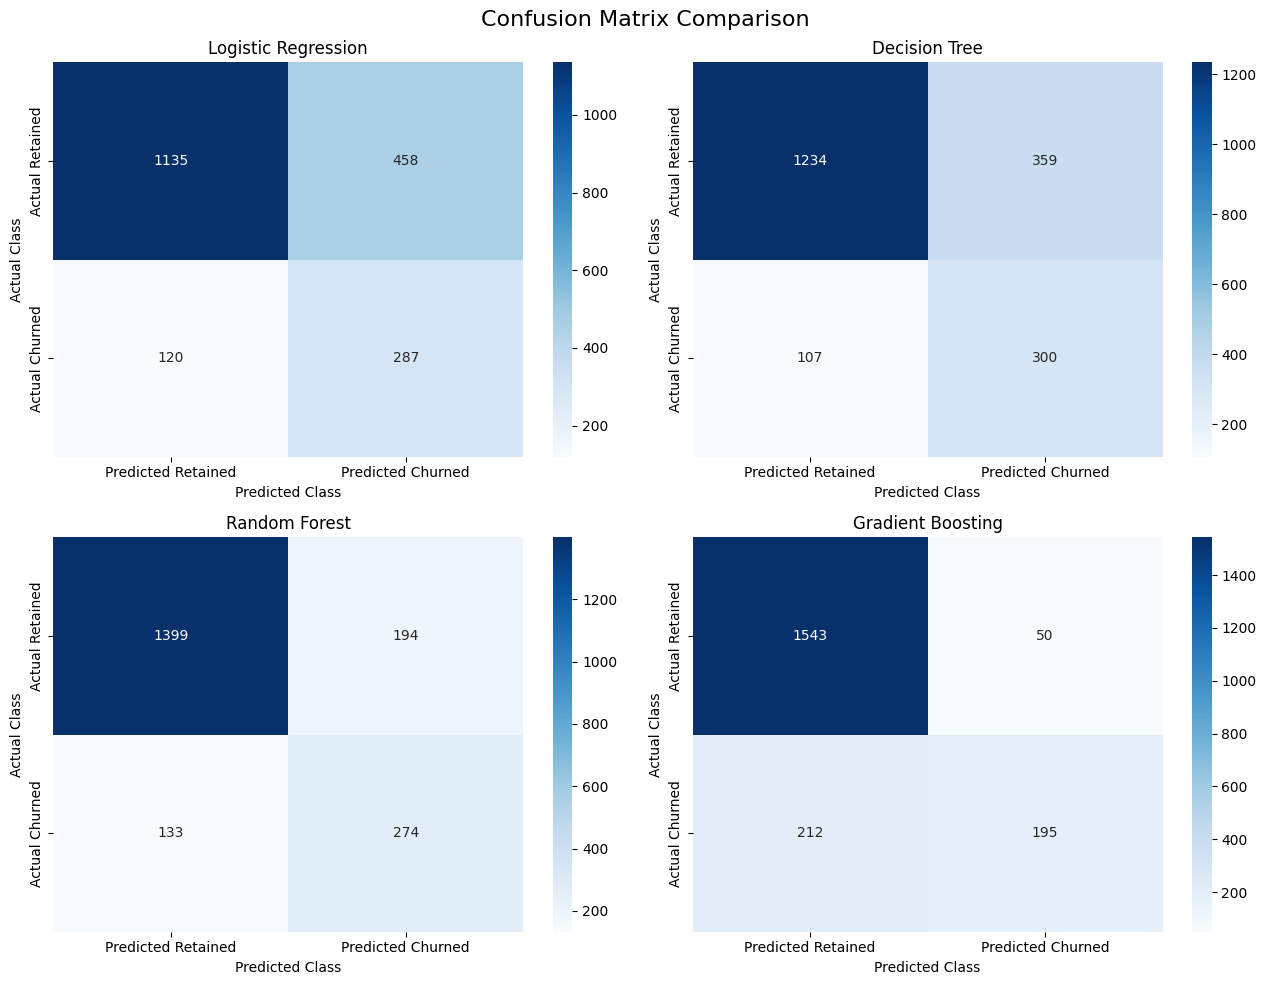

In [29]:
# Compare confusion matrices for all four models

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted Retained", "Predicted Churned"],
        yticklabels=["Actual Retained", "Actual Churned"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle("Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.show()

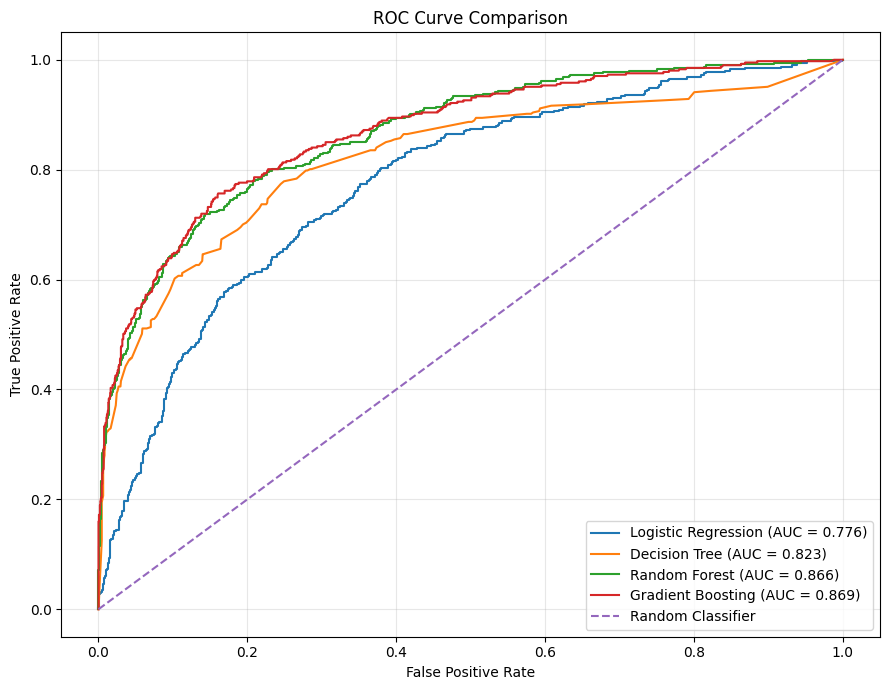

In [30]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 7))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Random Forest churn probabilities
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):
    y_threshold_pred = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.30,0.3832,0.8501,0.5282
1,0.35,0.4224,0.8157,0.5566
2,0.40,0.4804,0.7838,0.5957
3,0.45,0.5354,0.7248,0.6159
4,0.50,0.5855,0.6732,0.6263
5,0.55,0.6402,0.6339,0.6370
6,0.60,0.6903,0.5749,0.6273
7,0.65,0.7245,0.5233,0.6077
8,0.70,0.7815,0.4570,0.5767


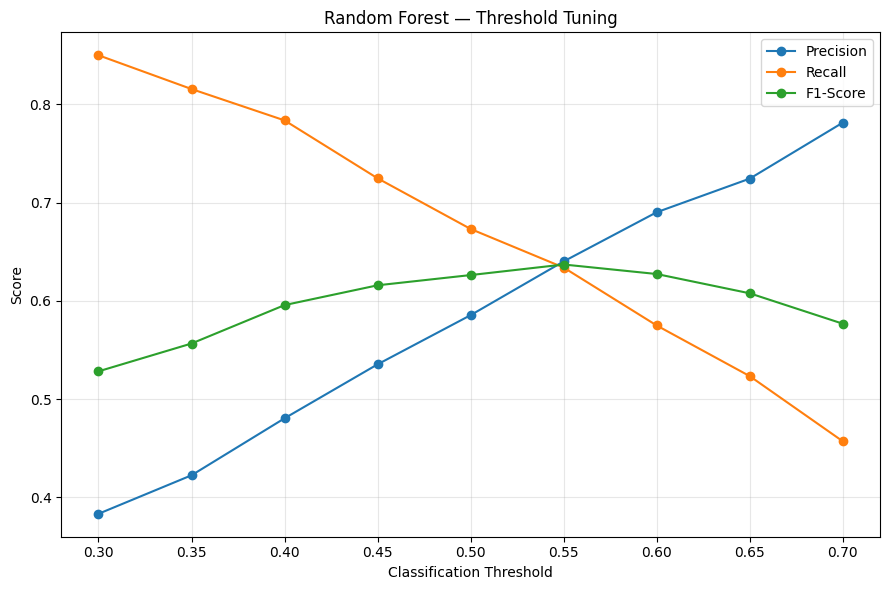

In [32]:
plt.figure(figsize=(9, 6))

for metric in ["Precision", "Recall", "F1-Score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest — Threshold Tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Extract transformed feature names from the fitted Random Forest pipeline

fitted_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()

rf_classifier = random_forest_model.named_steps["classifier"]

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.head(15).round(4))

,Feature,Importance
0,num__Age,0.2824
1,num__NumOfProducts,0.1665
2,num__Balance,0.0820
3,num__ProductEngagement,0.0711
4,num__AgeTenureInteraction,0.0662
5,num__EstimatedSalary,0.0570
6,num__BalanceSalaryRatio,0.0563
7,num__CreditScore,0.0557
8,cat__Geography_Germany,0.0383
9,num__Tenure,0.0319


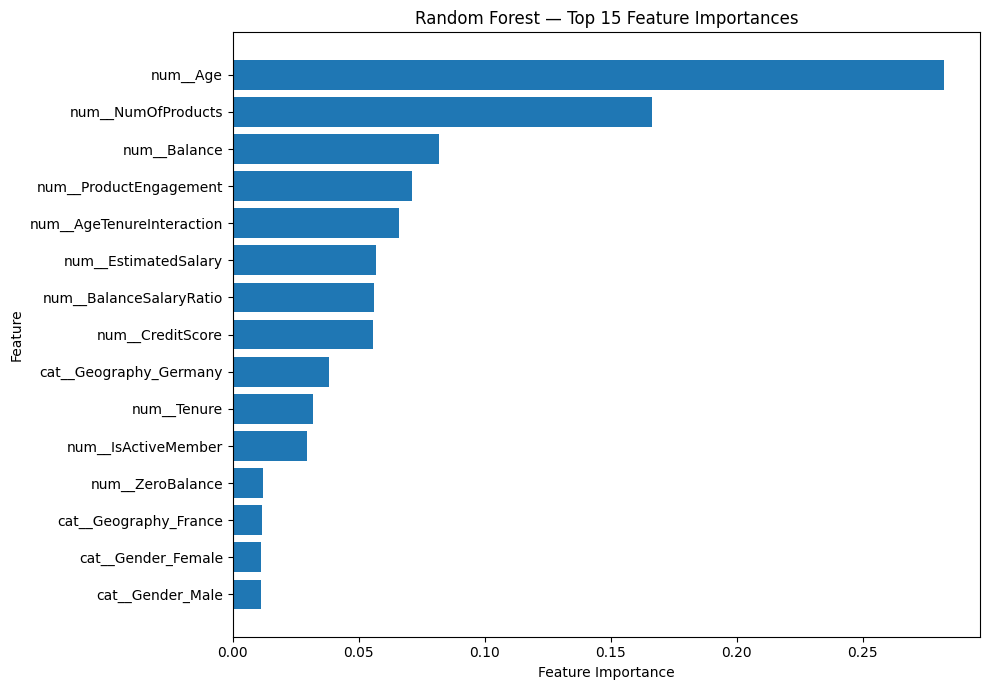

In [34]:
# Plot the 15 most important Random Forest features

top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [35]:
from sklearn.inspection import permutation_importance

# Measure the effect of shuffling each original input feature
# on the model's ROC-AUC.

permutation_result = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(permutation_importance_df.head(15).round(4))

,Feature,Importance_Mean,Importance_Std
0,Age,0.1084,0.0062
1,NumOfProducts,0.0758,0.0070
2,Geography,0.0270,0.0013
3,ProductEngagement,0.0151,0.0021
4,Balance,0.0147,0.0030
5,IsActiveMember,0.0083,0.0013
6,Gender,0.0080,0.0022
7,BalanceSalaryRatio,0.0041,0.0022
8,ZeroBalance,0.0013,0.0013
9,EstimatedSalary,-0.0001,0.0009


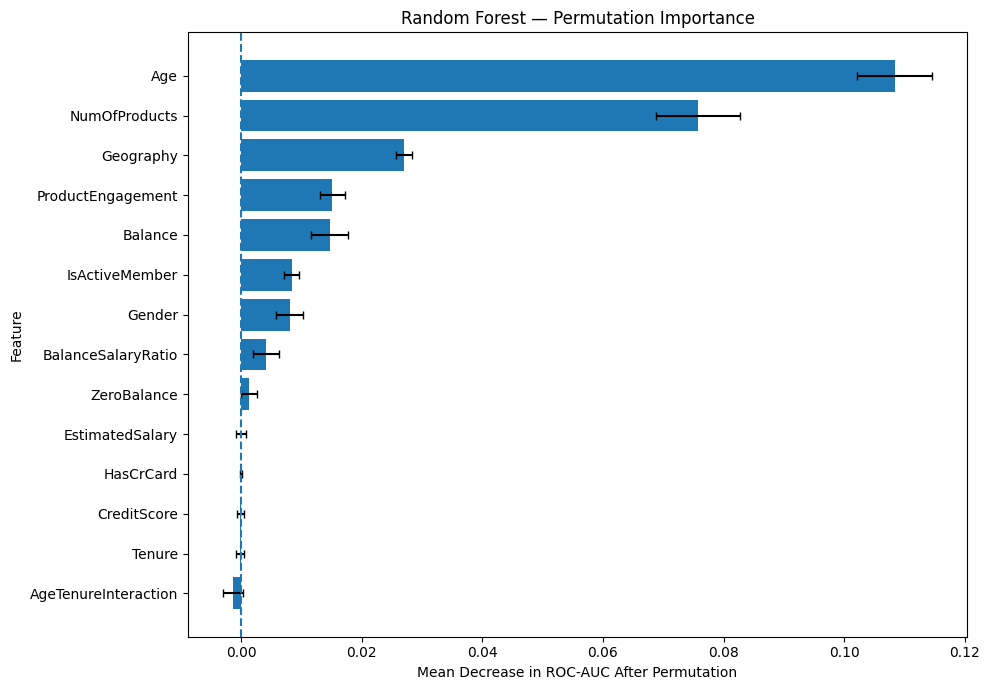

In [36]:
top_permutation = permutation_importance_df.head(15).sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance_Mean"],
    xerr=top_permutation["Importance_Std"],
    capsize=3
)

plt.axvline(0, linestyle="--")
plt.xlabel("Mean Decrease in ROC-AUC After Permutation")
plt.ylabel("Feature")
plt.title("Random Forest — Permutation Importance")
plt.tight_layout()
plt.show()

In [37]:
# Compare original features against engineered features

original_feature_columns = [
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

engineered_feature_columns = [
    "ZeroBalance",
    "BalanceSalaryRatio",
    "ProductEngagement",
    "AgeTenureInteraction"
]

X_original = X[original_feature_columns]

X_engineered = X[
    original_feature_columns + engineered_feature_columns
]

X_original_train = X_original.loc[X_train.index]
X_original_test = X_original.loc[X_test.index]

X_engineered_train = X_engineered.loc[X_train.index]
X_engineered_test = X_engineered.loc[X_test.index]

rf_original = Pipeline(steps=[
    ("preprocessor", preprocessor.__class__(
        transformers=[
            (
                "num",
                numeric_transformer,
                X_original_train.select_dtypes(
                    include=["int64", "float64"]
                ).columns.tolist()
            ),
            (
                "cat",
                categorical_transformer,
                X_original_train.select_dtypes(
                    include=["object", "category"]
                ).columns.tolist()
            )
        ]
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_engineered = Pipeline(steps=[
    ("preprocessor", ColumnTransformer(transformers=[
        (
            "num",
            numeric_transformer,
            X_engineered_train.select_dtypes(
                include=["int64", "float64"]
            ).columns.tolist()
        ),
        (
            "cat",
            categorical_transformer,
            X_engineered_train.select_dtypes(
                include=["object", "category"]
            ).columns.tolist()
        )
    ])),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_original.fit(X_original_train, y_train)
rf_engineered.fit(X_engineered_train, y_train)

comparison_rows = []

for name, model, X_eval in [
    ("Original Features", rf_original, X_original_test),
    ("Original + Engineered Features", rf_engineered, X_engineered_test)
]:
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]

    comparison_rows.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

feature_set_comparison = pd.DataFrame(
    comparison_rows
).set_index("Feature Set")

display(feature_set_comparison.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Feature Set,,,,,
Original Features,0.8335,0.5791,0.6658,0.6194,0.8604
Original + Engineered Features,0.8365,0.5855,0.6732,0.6263,0.8665


In [38]:
# Create training and validation subsets
# Preserve the original test set for the final evaluation.

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)
print("Final test set:", X_test.shape)

print("\nChurn prevalence:")
print("Training:", round(y_train_sub.mean(), 4))
print("Validation:", round(y_val.mean(), 4))
print("Test:", round(y_test.mean(), 4))

Training subset: (6400, 14)
Validation set: (1600, 14)
Final test set: (2000, 14)

Churn prevalence:
Training: 0.2037
Validation: 0.2037
Test: 0.2035


In [39]:
# Train the candidate Random Forest using training data only.

rf_candidate = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_candidate.fit(X_train_sub, y_train_sub)

print("Candidate Random Forest trained successfully.")

Candidate Random Forest trained successfully.


In [41]:
# Generate churn probabilities for validation records.

val_probabilities = rf_candidate.predict_proba(X_val)[:, 1]

validation_threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    validation_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

validation_threshold_df = pd.DataFrame(
    validation_threshold_results
)

display(validation_threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.30,0.3849,0.8620,0.5322
1,0.35,0.4401,0.8221,0.5733
2,0.40,0.4893,0.7699,0.5983
3,0.45,0.5283,0.7147,0.6076
4,0.50,0.5930,0.6748,0.6313
5,0.55,0.6364,0.6012,0.6183
6,0.60,0.6860,0.5429,0.6062
7,0.65,0.7387,0.5031,0.5985
8,0.70,0.7842,0.4571,0.5775


In [42]:
best_row = validation_threshold_df.loc[
    validation_threshold_df["F1-Score"].idxmax()
]

selected_threshold = float(best_row["Threshold"])

print("Selected validation threshold:", selected_threshold)
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1-Score"], 4))

Selected validation threshold: 0.5
Validation precision: 0.593
Validation recall: 0.6748
Validation F1-score: 0.6313


In [43]:
# Final evaluation on the held-out test set

final_probabilities = rf_candidate.predict_proba(X_test)[:, 1]

final_predictions = (
    final_probabilities >= selected_threshold
).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(
        y_test, final_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, final_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, final_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, final_probabilities)
}

final_results = pd.DataFrame(
    [final_metrics],
    index=["Final Random Forest"]
)

display(final_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["Retained", "Churned"],
    zero_division=0
))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Final Random Forest,0.839,0.593,0.6658,0.6273,0.865



Classification Report:
              precision    recall  f1-score   support

    Retained       0.91      0.88      0.90      1593
     Churned       0.59      0.67      0.63       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.85      0.84      0.84      2000



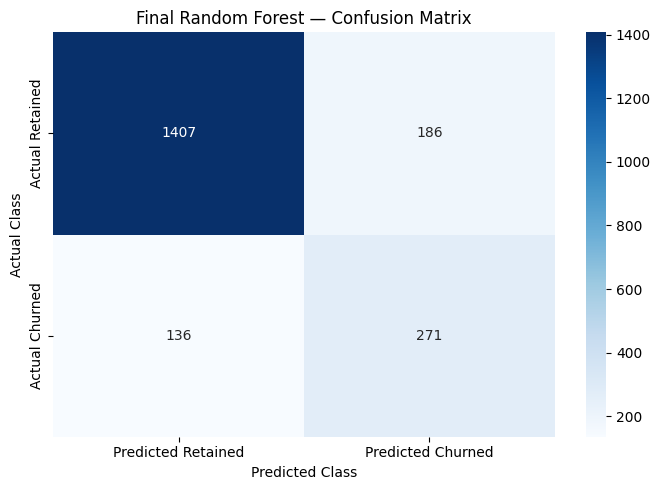

In [44]:
# Final confusion matrix

final_cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Retained", "Predicted Churned"],
    yticklabels=["Actual Retained", "Actual Churned"]
)

plt.title("Final Random Forest — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [45]:
# Generate customer-level churn risk scores

customer_risk = X_test.copy()

customer_risk["Actual_Churn"] = y_test

customer_risk["Churn_Probability"] = final_probabilities

customer_risk["Churn_Probability_Percent"] = (
    customer_risk["Churn_Probability"] * 100
).round(2)

customer_risk["Predicted_Churn"] = final_predictions

customer_risk["Risk_Category"] = pd.cut(
    customer_risk["Churn_Probability"],
    bins=[-0.001, 0.30, 0.50, 0.70, 1.001],
    labels=["Low", "Moderate", "High", "Critical"],
    right=False
)

customer_risk = customer_risk.sort_values(
    by="Churn_Probability",
    ascending=False
)

display(customer_risk.head(20))

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,ZeroBalance,BalanceSalaryRatio,ProductEngagement,AgeTenureInteraction,Actual_Churn,Churn_Probability,Churn_Probability_Percent,Predicted_Churn,Risk_Category
6831,469,Germany,Female,52,8,139493.25,3,0,0,150093.32,0,0.929377,0,416,1,0.958956,95.90,1,Critical
1955,565,Germany,Female,58,3,108888.24,3,0,1,135875.51,0,0.801382,3,174,1,0.957763,95.78,1,Critical
5950,834,Germany,Female,57,8,112281.60,3,1,0,140225.14,0,0.800724,0,456,1,0.953311,95.33,1,Critical
5010,575,Germany,Male,49,7,121205.15,4,1,1,168080.53,0,0.721114,4,343,1,0.950040,95.00,1,Critical
4153,695,Germany,Female,53,8,95231.91,1,0,0,70140.80,0,1.357725,0,424,1,0.948889,94.89,1,Critical
776,622,Germany,Female,58,7,116922.25,1,1,0,120415.61,0,0.970989,0,406,1,0.947699,94.77,1,Critical
7435,610,Spain,Female,50,5,130554.51,3,1,0,184758.17,0,0.706624,0,250,1,0.947171,94.72,1,Critical
3549,675,France,Female,61,5,62055.17,3,1,0,166305.16,0,0.373140,0,305,1,0.947142,94.71,1,Critical
4732,638,Germany,Female,53,1,123916.67,1,1,0,16657.68,0,7.439011,0,53,1,0.945664,94.57,1,Critical
2518,758,France,Female,50,2,95813.76,3,1,1,67944.09,0,1.410185,3,100,1,0.940711,94.07,1,Critical


,count
Risk_Category,
Low,1092
Moderate,451
High,217
Critical,240


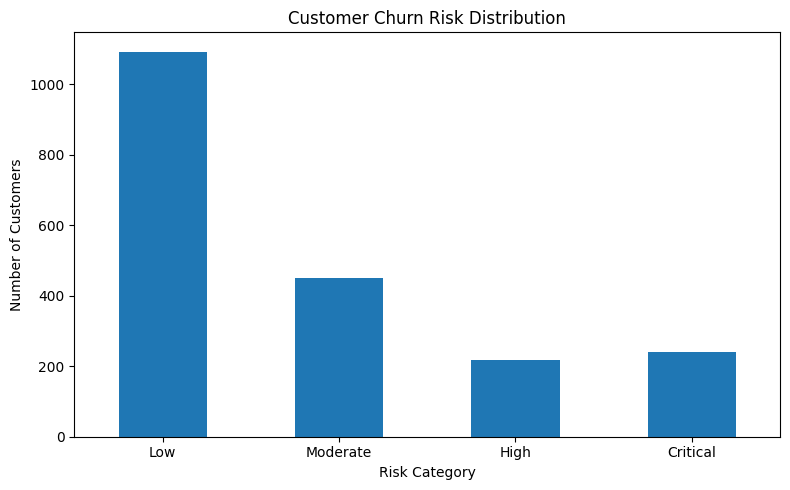

In [46]:
# Analyze customer risk distribution

risk_distribution = (
    customer_risk["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Moderate", "High", "Critical"])
)

display(risk_distribution)

plt.figure(figsize=(8, 5))

risk_distribution.plot(kind="bar")

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
# Export customer-level predictions

customer_risk.to_csv(
    "customer_churn_risk_scores.csv",
    index=True
)

print("Customer churn risk scores exported successfully.")

Customer churn risk scores exported successfully.


In [48]:
# Create operational customer risk scores

operational_risk = customer_risk.copy()

# Restore original customer identifiers using dataframe indices
operational_risk["CustomerId"] = df.loc[
    operational_risk.index, "CustomerId"
]

# Remove actual target labels from operational predictions
operational_risk = operational_risk.drop(
    columns=["Actual_Churn"],
    errors="ignore"
)

# Arrange important columns first
priority_columns = [
    "CustomerId",
    "Churn_Probability",
    "Churn_Probability_Percent",
    "Predicted_Churn",
    "Risk_Category"
]

remaining_columns = [
    col for col in operational_risk.columns
    if col not in priority_columns
]

operational_risk = operational_risk[
    priority_columns + remaining_columns
]

display(operational_risk.head(10))

,CustomerId,Churn_Probability,Churn_Probability_Percent,Predicted_Churn,Risk_Category,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,ZeroBalance,BalanceSalaryRatio,ProductEngagement,AgeTenureInteraction
6831,15696989,0.958956,95.90,1,Critical,469,Germany,Female,52,8,139493.25,3,0,0,150093.32,0,0.929377,0,416
1955,15779176,0.957763,95.78,1,Critical,565,Germany,Female,58,3,108888.24,3,0,1,135875.51,0,0.801382,3,174
5950,15806808,0.953311,95.33,1,Critical,834,Germany,Female,57,8,112281.60,3,1,0,140225.14,0,0.800724,0,456
5010,15719508,0.950040,95.00,1,Critical,575,Germany,Male,49,7,121205.15,4,1,1,168080.53,0,0.721114,4,343
4153,15664001,0.948889,94.89,1,Critical,695,Germany,Female,53,8,95231.91,1,0,0,70140.80,0,1.357725,0,424
776,15712551,0.947699,94.77,1,Critical,622,Germany,Female,58,7,116922.25,1,1,0,120415.61,0,0.970989,0,406
7435,15647898,0.947171,94.72,1,Critical,610,Spain,Female,50,5,130554.51,3,1,0,184758.17,0,0.706624,0,250
3549,15647725,0.947142,94.71,1,Critical,675,France,Female,61,5,62055.17,3,1,0,166305.16,0,0.373140,0,305
4732,15653937,0.945664,94.57,1,Critical,638,Germany,Female,53,1,123916.67,1,1,0,16657.68,0,7.439011,0,53
2518,15759436,0.940711,94.07,1,Critical,758,France,Female,50,2,95813.76,3,1,1,67944.09,0,1.410185,3,100


In [49]:
operational_risk.to_csv(
    "operational_customer_churn_risk.csv",
    index=False
)

print("Operational risk dataset exported successfully.")

Operational risk dataset exported successfully.


In [50]:
import joblib

model_artifacts = {
    "model": rf_candidate,
    "threshold": selected_threshold,
    "feature_columns": X_train.columns.tolist(),
    "risk_categories": {
        "Low": [0.0, 0.30],
        "Moderate": [0.30, 0.50],
        "High": [0.50, 0.70],
        "Critical": [0.70, 1.0]
    }
}

joblib.dump(
    model_artifacts,
    "bank_churn_model.pkl"
)

print("Model artifacts saved successfully.")

Model artifacts saved successfully.


#Dashboard

In [51]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 57.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 86.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [52]:
import streamlit as st
import joblib
import pandas as pd
import numpy as np

In [54]:
!mkdir -p .streamlit

In [55]:
%%writefile .streamlit/config.toml
[theme]
base = "light"
primaryColor = "#003299"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#F4F6FB"
textColor = "#333333"
font = "sans serif"

Writing .streamlit/config.toml


In [66]:
%%writefile app.py

import html
import streamlit as st
import pandas as pd
import altair as alt

st.set_page_config(
    page_title="Customer Churn Risk Dashboard",
    layout="wide"
)

# ---------- Palette ----------
NAVY = "#003299"
YELLOW = "#FFB400"
ORANGE = "#FF4B00"
GREEN = "#65B800"
SKY = "#00B1EA"
GREY = "#5C5C5C"

RISK_COLORS = {"Low": GREEN, "Moderate": SKY, "High": YELLOW, "Critical": ORANGE}
risk_options = list(RISK_COLORS.keys())

# ---------- Styling ----------
st.markdown("""
<style>
html, body, .stApp, [class*="css"] { font-family: Arial, Helvetica, sans-serif; }
.stApp { background: #FFFFFF; color: #333333; }
.block-container { padding-top: 0.5rem; max-width: 1280px; }
header[data-testid="stHeader"] { background: transparent; }
h1, h2, h3 { color: #003299; font-family: Arial, Helvetica, sans-serif; }

/* Top bar + navigation */
.top-bar { display:flex; justify-content:space-between; align-items:flex-end;
           padding:18px 0 12px; border-bottom:1px solid #D9DEE8; }
.brand-title { font-size:1.35rem; font-weight:700; color:#003299; line-height:1.2; }
.brand-sub { font-size:.75rem; color:#5C5C5C; letter-spacing:.06em; text-transform:uppercase; }
.top-meta { font-size:.8rem; color:#5C5C5C; }
.nav-bar { display:flex; flex-wrap:wrap; gap:28px; padding:12px 0;
           border-bottom:3px solid #003299; margin-bottom:28px; }
.nav-bar a { color:#003299 !important; text-decoration:none !important;
             font-weight:700; font-size:.92rem; }
.nav-bar a:hover { color:#FFB400 !important; }

/* Feature banner */
.hero { background:#003299; padding:36px 40px; margin-bottom:32px; }
.hero .label { color:#FFB400; }
.hero h1 { color:#FFFFFF !important; font-size:2.1rem; margin:6px 0 10px; padding:0; }
.hero p { max-width:780px; color:#E6EAF5; font-size:1rem; line-height:1.55; margin:0; }

/* Labels + section titles */
.label { font-size:.72rem; font-weight:700; letter-spacing:.08em;
         text-transform:uppercase; color:#5C5C5C; }
.section-title { font-size:1.45rem; font-weight:700; color:#003299;
                 margin:36px 0 14px; padding-bottom:8px; border-bottom:1px solid #D9DEE8; }

/* KPI cards */
.kpi { border-top:4px solid #003299; background:#F4F6FB; padding:18px 20px; }
.kpi.high { border-top-color:#FFB400; }
.kpi.critical { border-top-color:#FF4B00; }
.kpi .value { font-size:2rem; font-weight:700; color:#003299; margin-top:6px; }
.kpi .note { font-size:.8rem; color:#5C5C5C; }

/* News-feed style list */
.feed-item { padding:14px 0; border-bottom:1px solid #D9DEE8; }
.feed-item .meta { font-size:.72rem; color:#5C5C5C; text-transform:uppercase; letter-spacing:.06em; }
.feed-item .title { color:#003299; font-weight:700; font-size:1rem; margin-top:4px; }
.pill { display:inline-block; padding:1px 8px; font-size:.68rem; font-weight:700;
        color:#FFFFFF; margin-right:8px; }

/* Sidebar */
section[data-testid="stSidebar"] { background:#F4F6FB; border-right:1px solid #D9DEE8; }
section[data-testid="stSidebar"] h2 { color:#003299; font-size:1rem;
        text-transform:uppercase; letter-spacing:.08em; }

/* Download button */
.stDownloadButton button { background:#003299; color:#FFFFFF; border:none; border-radius:0;
        font-weight:700; padding:.65rem 1.4rem; text-transform:uppercase;
        letter-spacing:.06em; font-size:.8rem; }
.stDownloadButton button:hover { background:#FFB400; color:#003299; border:none; }

/* Footer */
.footer { background:#003299; color:#C9D3EE; padding:28px 40px; margin-top:48px; font-size:.8rem; }
.footer strong { color:#FFFFFF; }
</style>
""", unsafe_allow_html=True)

# ---------- Data ----------
@st.cache_data
def load_data():
    return pd.read_csv("operational_customer_churn_risk.csv")

df = load_data()

# ---------- Sidebar filters ----------
st.sidebar.header("Filters")

selected_risks = st.sidebar.multiselect(
    "Risk categories", risk_options, default=risk_options
)

if "Geography" in df.columns:
    geography_options = sorted(df["Geography"].dropna().unique())
    selected_geographies = st.sidebar.multiselect(
        "Geography", geography_options, default=geography_options
    )
else:
    selected_geographies = []

filtered_df = df[df["Risk_Category"].isin(selected_risks)]
if "Geography" in df.columns:
    filtered_df = filtered_df[filtered_df["Geography"].isin(selected_geographies)]

sort_col = "Churn_Probability" if "Churn_Probability" in df.columns else "Churn_Probability_Percent"
pct_col = "Churn_Probability_Percent"

# ---------- Header ----------
today = pd.Timestamp.today().strftime("%d %B %Y")

st.markdown(f"""
<div class="top-bar">
  <div>
    <div class="brand-sub">Risk Analytics</div>
    <div class="brand-title">Customer Churn Risk Dashboard</div>
  </div>
  <div class="top-meta">Updated {today}</div>
</div>
<div class="nav-bar">
  <a href="#overview">Overview</a>
  <a href="#distribution">Risk distribution</a>
  <a href="#records">Customer records</a>
  <a href="#report">Report</a>
</div>
<div class="hero" id="overview">
  <div class="label">Model output</div>
  <h1>Predictive modelling and risk scoring for customer churn</h1>
  <p>Churn-risk predictions generated by a Random Forest classification model.
     Use the filters to focus on specific risk categories or geographies.</p>
</div>
""", unsafe_allow_html=True)

# ---------- KPIs ----------
total = len(filtered_df)
high = int((filtered_df["Risk_Category"] == "High").sum())
critical = int((filtered_df["Risk_Category"] == "Critical").sum())
avg_score = f"{filtered_df[pct_col].mean():.2f}%" if not filtered_df.empty else "N/A"

def kpi(label, value, note, cls=""):
    return f"""<div class="kpi {cls}">
      <div class="label">{label}</div>
      <div class="value">{value}</div>
      <div class="note">{note}</div></div>"""

c1, c2, c3, c4 = st.columns(4)
c1.markdown(kpi("Total customers", f"{total:,}", "In current selection"), unsafe_allow_html=True)
c2.markdown(kpi("High risk", f"{high:,}", "Customers flagged High", "high"), unsafe_allow_html=True)
c3.markdown(kpi("Critical risk", f"{critical:,}", "Customers flagged Critical", "critical"), unsafe_allow_html=True)
c4.markdown(kpi("Average churn score", avg_score, "Mean predicted probability"), unsafe_allow_html=True)

# ---------- Distribution + top-risk feed ----------
left, right = st.columns([2, 1], gap="large")

with left:
    st.markdown('<div class="section-title" id="distribution">Customer risk distribution</div>',
                unsafe_allow_html=True)
    if not filtered_df.empty:
        risk_counts = (
            filtered_df["Risk_Category"].value_counts()
            .reindex(risk_options, fill_value=0)
            .rename_axis("Risk_Category")
            .reset_index(name="Customers")
        )
        chart = (
            alt.Chart(risk_counts)
            .mark_bar(size=56)
            .encode(
                x=alt.X("Risk_Category:N", sort=risk_options, title=None,
                        axis=alt.Axis(labelAngle=0)),
                y=alt.Y("Customers:Q", title="Customers"),
                color=alt.Color("Risk_Category:N",
                                scale=alt.Scale(domain=risk_options,
                                                range=list(RISK_COLORS.values())),
                                legend=None),
                tooltip=["Risk_Category", "Customers"],
            )
            .properties(height=330)
            .configure_axis(labelFont="Arial", titleFont="Arial",
                            labelColor=GREY, titleColor=GREY,
                            gridColor="#E6EAF2", domainColor="#D9DEE8")
            .configure_view(strokeWidth=0)
        )
        st.altair_chart(chart, use_container_width=True)
    else:
        st.info("No customers match the current filters.")

with right:
    st.markdown('<div class="section-title">Highest-risk customers</div>',
                unsafe_allow_html=True)
    id_col = next((c for c in ["CustomerId", "Customer_ID", "CustomerID", "Surname"]
                   if c in filtered_df.columns), None)
    top = filtered_df.sort_values(sort_col, ascending=False).head(5)
    items = ""
    for idx, row in top.iterrows():
        cat = row["Risk_Category"]
        name = html.escape(str(row[id_col])) if id_col else f"Record {idx}"
        geo = f" · {html.escape(str(row['Geography']))}" if "Geography" in row else ""
        items += f"""<div class="feed-item">
          <div class="meta"><span class="pill" style="background:{RISK_COLORS.get(cat, NAVY)}">{cat}</span>
          {row[pct_col]:.1f}% churn probability{geo}</div>
          <div class="title">Customer {name}</div></div>"""
    st.markdown(items or "<p>No records.</p>", unsafe_allow_html=True)

# ---------- Records table ----------
st.markdown('<div class="section-title" id="records">Customer risk records</div>',
            unsafe_allow_html=True)

col_cfg = {}
if pct_col in filtered_df.columns:
    col_cfg[pct_col] = st.column_config.ProgressColumn(
        "Churn probability", min_value=0, max_value=100, format="%.1f%%"
    )

st.dataframe(
    filtered_df.sort_values(sort_col, ascending=False),
    use_container_width=True,
    hide_index=True,
    column_config=col_cfg,
)

# ---------- Download ----------
st.markdown('<div class="section-title" id="report">Report</div>', unsafe_allow_html=True)
st.download_button(
    label="Download filtered risk report",
    data=filtered_df.to_csv(index=False).encode("utf-8"),
    file_name="filtered_customer_churn_risk.csv",
    mime="text/csv",
)

# ---------- Footer ----------
st.markdown(f"""
<div class="footer">
  <strong>Customer Churn Risk Dashboard</strong><br>
  Predictions from a Random Forest classification model · Generated {today}<br>
  For internal analytical use.
</div>
""", unsafe_allow_html=True)

Overwriting app.py


In [57]:
import os

print(os.listdir())

['.config', 'customer_churn_risk_scores.csv', 'bank_churn_model.pkl', 'European_Bank.csv', 'app.py', 'operational_customer_churn_risk.csv', '.streamlit', 'sample_data']


In [58]:
!pip install pyngrok

In [60]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 4s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.3
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.3
npm notice To update run: npm install -g npm@12.2.3
npm notice
⠏

In [64]:
import subprocess
import time

tunnel = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(5)

print(tunnel.stdout.readline())

your url is: https://quiet-lizards-dream.loca.lt



In [67]:
!pkill -f streamlit
!pkill -f localtunnel
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

import subprocess, time, re

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(8)

tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in tunnel.stdout:
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        print("OPEN THIS LINK:", m.group(0))
        break

cloudflared: Text file busy
OPEN THIS LINK: https://personals-mason-weather-yard.trycloudflare.com


In [68]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".config", "sample_data", "__pycache__"]]

    for file in files:
        print(os.path.join(root, file))

./customer_churn_risk_scores.csv
./bank_churn_model.pkl
./European_Bank.csv
./cloudflared
./app.py
./operational_customer_churn_risk.csv
./.streamlit/config.toml


In [69]:
from getpass import getpass

github_token = getpass("Paste your GitHub token: ")
github_username = input("Enter your GitHub username: ")

Paste your GitHub token: ··········
Enter your GitHub username: Bhairavi-28


In [70]:
repo_name = "Bank-Customer-Churn-Prediction"

print("GitHub username:", github_username)
print("Repository:", repo_name)

GitHub username: Bhairavi-28
Repository: Bank-Customer-Churn-Prediction


In [71]:
import os

required_files = [
    "app.py",
    "bank_churn_model.pkl",
    "operational_customer_churn_risk.csv",
    "European_Bank.csv"
]

for file in required_files:
    print(f"{'✓' if os.path.exists(file) else '✗'} {file}")

print("\nCurrent directory:", os.getcwd())

✓ app.py
✓ bank_churn_model.pkl
✓ operational_customer_churn_risk.csv
✓ European_Bank.csv

Current directory: /content


In [72]:
!git --version

git version 2.43.0


In [73]:
import os
import glob

print("NOTEBOOKS:")
for file in glob.glob("/content/*.ipynb"):
    print(file, "-", round(os.path.getsize(file) / 1024, 2), "KB")

print("\nPROJECT FILE SIZES:")
for file in [
    "app.py",
    "bank_churn_model.pkl",
    "operational_customer_churn_risk.csv",
    "European_Bank.csv"
]:
    size = os.path.getsize(file) / (1024 * 1024)
    print(f"{file}: {size:.2f} MB")

NOTEBOOKS:

PROJECT FILE SIZES:
app.py: 0.01 MB
bank_churn_model.pkl: 7.24 MB
operational_customer_churn_risk.csv: 0.21 MB
European_Bank.csv: 0.65 MB
